# Tóm tắt quy trình & Kết quả: `dnn_np.py` và `dnn_tf.py` (EE3169 - HW2)

Kiến trúc chung `[100, 100, 100]` (`ReLU`) + `Softmax` cho 2 bài toán:
- **Bat (`data/bat.dat`)**: 3 lớp, 2 đặc trưng (`(12000, 2)` train / `(3000, 2)` test).
- **Fashion MNIST (`data/fashion-mnist/*.gz`)**: 10 lớp, ảnh `28x28 = 784` pixel (`(50000, 784)` train / `(10000, 784)` val / `(10000, 784)` test).

## 1. Tiền xử lý dữ liệu (`util.py`)

1. Đọc dữ liệu bằng `get_bat_data()` và `get_mnist_data(1)`.
2. Chuẩn hóa theo `mean` và `std` tập train qua `normalize(train_x, train_x, test_x)`.
3. Khác biệt xử lý bias:
   - `dnn_np.py`: gọi `add_one()` thêm cột `1.0` vào cuối vector đặc trưng (gộp bias vào ma trận trọng số `w`).
   - `dnn_tf.py`: giữ nguyên shape đầu vào vì các tầng `Dense` tự quản lý bias riêng.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import matplotlib.pyplot as plt
import util
import dnn_np
import importlib
importlib.reload(dnn_np)

bat_tr_x, bat_tr_y, bat_te_x, bat_te_y = util.get_bat_data()
bat_tr_norm, _, bat_te_norm = util.normalize(bat_tr_x, bat_tr_x, bat_te_x)
bat_tr_bias = util.add_one(bat_tr_norm)

mnist_tr_x, mnist_tr_y, mnist_val_x, mnist_val_y, mnist_te_x, mnist_te_y = util.get_mnist_data(1)
mnist_tr_norm, _, mnist_te_norm = util.normalize(mnist_tr_x, mnist_tr_x, mnist_te_x)
mnist_tr_bias = util.add_one(mnist_tr_norm)

print(f"Bat  : raw={bat_tr_x.shape}, normalize={bat_tr_norm.shape}, add_one={bat_tr_bias.shape}, test={bat_te_x.shape}")
print(f"MNIST: raw={mnist_tr_x.shape}, normalize={mnist_tr_norm.shape}, add_one={mnist_tr_bias.shape}, val={mnist_val_x.shape}, test={mnist_te_x.shape}")

Reading bat data...
EOF Reached
Done reading
Reading fashion MNIST data...
Done reading
Bat  : raw=(12000, 2), normalize=(12000, 2), add_one=(12000, 3), test=(3000, 2)
MNIST: raw=(50000, 784), normalize=(50000, 784), add_one=(50000, 785), val=(10000, 784), test=(10000, 784)


## 2. Luồng hoạt động & Kết quả của `dnn_np.py`

1. **`Config`, `Layer`, `NeuralNet`** (đồng bộ tham số với `dnn_tf.py`):
   - Bat: `num_epoch=200, batch_size=200, learning_rate=0.005, momentum_rate=0.9, reg=0.00015`.
   - Fashion MNIST: `num_epoch=60, batch_size=200, learning_rate=0.001, momentum_rate=0.9, reg=0.00015, visualize=False`.
   - Khởi tạo $W \sim \mathcal{N}(0, \sqrt{2/(D_{\text{in}}+D_{\text{out}})})$ và `momentum = 0`.
2. **`forward()`**: tính $z^{(l)} = a^{(l-1)}W^{(l)}$, kích hoạt (`sigmoid`, `tanh`, `relu`, tầng cuối `softmax_minus_max`), lưu `all_x`.
3. **`compute_loss()`**: chuyển nhãn sang One-Hot (`create_one_hot`), tính Cross-Entropy trung bình (clip $\hat{y} \in [10^{-12}, 1-10^{-12}]$) + L2 regularization $0.5 \sum \lambda_l \|W^{(l)}\|_F^2$.
4. **`backward()`**: tầng cuối $\delta^{(L)} = (\hat{y}-y)/m$; lặp ngược qua các tầng ẩn $\delta^{(l)} = (\delta^{(l+1)}W^{(l+1)T}) \odot \sigma'(a^{(l)})$, $\nabla W^{(l)} = a^{(l-1)T}\delta^{(l)} + \lambda_l W^{(l)}$.
5. **`minibatch_train()` / `batch_train()` & `test()`**: xáo trộn dữ liệu mỗi epoch, cập nhật SGD/Momentum, tính Confusion Matrix chuẩn hóa và đường chéo chính.

In [2]:
np.random.seed(2017)
for act in ['sigmoid', 'tanh', 'relu']:
    print(f"unit_test_layer({act}):", end=" ")
    dnn_np.unit_test_layer(dnn_np.Layer((60, 100), act))

unit_test_layer(sigmoid): Relative error between numerical grad and function grad is: 1.332183e-09
unit_test_layer(tanh): Relative error between numerical grad and function grad is: 1.565342e-09
unit_test_layer(relu): Relative error between numerical grad and function grad is: 9.317876e-10


Reading bat data...
EOF Reached
Done reading
Epoch 1: loss is 1.00604
Epoch 2: loss is 1.00234
Epoch 3: loss is 0.99924
Epoch 4: loss is 0.99671
Epoch 5: loss is 0.99323
Epoch 6: loss is 0.98920
Epoch 7: loss is 0.98528
Epoch 8: loss is 0.97923
Epoch 9: loss is 0.97305
Epoch 10: loss is 0.96511
Epoch 11: loss is 0.95500
Epoch 12: loss is 0.94175
Epoch 13: loss is 0.92374
Epoch 14: loss is 0.89948
Epoch 15: loss is 0.86799
Epoch 16: loss is 0.82825
Epoch 17: loss is 0.78068
Epoch 18: loss is 0.73604
Epoch 19: loss is 0.69888
Epoch 20: loss is 0.66619
Epoch 21: loss is 0.63962
Epoch 22: loss is 0.60276
Epoch 23: loss is 0.58425
Epoch 24: loss is 0.55587
Epoch 25: loss is 0.54688
Epoch 26: loss is 0.52319
Epoch 27: loss is 0.51560
Epoch 28: loss is 0.48909
Epoch 29: loss is 0.47042
Epoch 30: loss is 0.46260
Epoch 31: loss is 0.44086
Epoch 32: loss is 0.44147
Epoch 33: loss is 0.43301
Epoch 34: loss is 0.42107
Epoch 35: loss is 0.40410
Epoch 36: loss is 0.39556
Epoch 37: loss is 0.39533
Ep

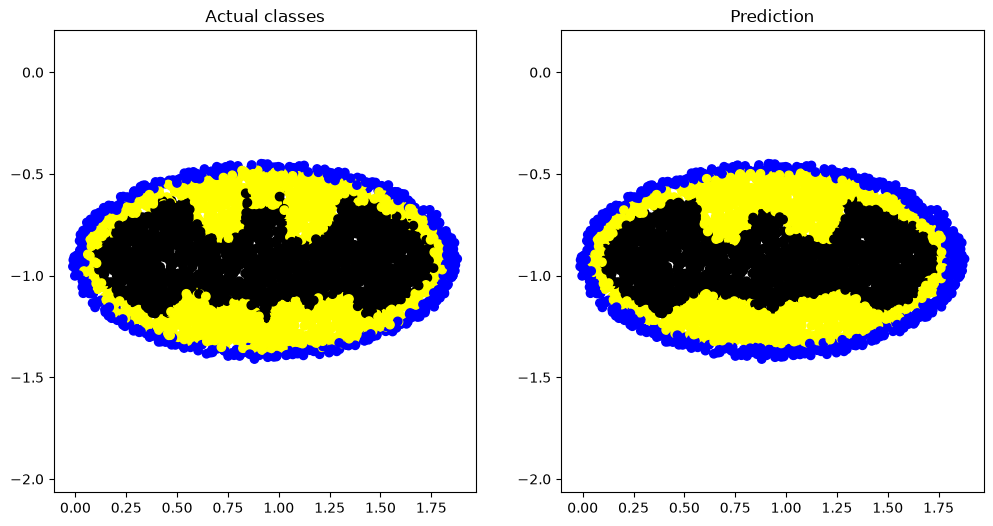

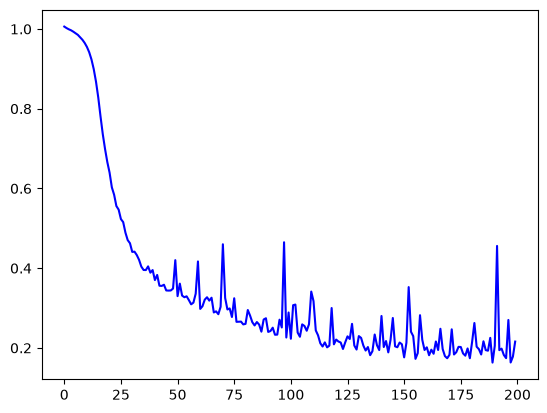

Epoch 200: loss is 0.21595
Confusion matrix:
[[0.93 0.07 0.  ]
 [0.02 0.89 0.09]
 [0.   0.05 0.95]]
Diagonal values:
[0.93 0.89 0.95]


In [3]:
np.random.seed(2017)
dnn_np.bat_classification()

Reading fashion MNIST data...
Done reading
Epoch 1: loss is 0.68312
Epoch 2: loss is 0.56273
Epoch 3: loss is 0.51375
Epoch 4: loss is 0.48073
Epoch 5: loss is 0.46310
Epoch 6: loss is 0.45173
Epoch 7: loss is 0.43444
Epoch 8: loss is 0.42788
Epoch 9: loss is 0.41518
Epoch 10: loss is 0.40447
Epoch 11: loss is 0.39555
Epoch 12: loss is 0.38957
Epoch 13: loss is 0.38501
Epoch 14: loss is 0.37796
Epoch 15: loss is 0.37751
Epoch 16: loss is 0.37123
Epoch 17: loss is 0.36409
Epoch 18: loss is 0.36337
Epoch 19: loss is 0.35274
Epoch 20: loss is 0.35273
Epoch 21: loss is 0.34696
Epoch 22: loss is 0.34472
Epoch 23: loss is 0.34928
Epoch 24: loss is 0.34047
Epoch 25: loss is 0.33460
Epoch 26: loss is 0.33272
Epoch 27: loss is 0.32679
Epoch 28: loss is 0.32118
Epoch 29: loss is 0.32206
Epoch 30: loss is 0.31937
Epoch 31: loss is 0.31644
Epoch 32: loss is 0.31150
Epoch 33: loss is 0.31317
Epoch 34: loss is 0.30975
Epoch 35: loss is 0.31064
Epoch 36: loss is 0.30201
Epoch 37: loss is 0.30246
Epoc

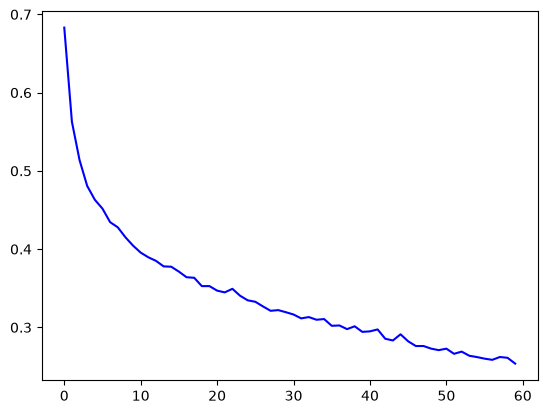

Epoch 60: loss is 0.25372
Confusion matrix:
[[0.83 0.   0.03 0.03 0.01 0.   0.09 0.   0.01 0.  ]
 [0.   0.96 0.   0.03 0.   0.   0.   0.   0.   0.  ]
 [0.02 0.   0.81 0.02 0.11 0.   0.04 0.   0.   0.  ]
 [0.03 0.01 0.02 0.89 0.03 0.   0.02 0.   0.01 0.  ]
 [0.   0.   0.09 0.02 0.85 0.   0.04 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.95 0.   0.03 0.   0.02]
 [0.13 0.   0.11 0.04 0.09 0.   0.63 0.   0.01 0.  ]
 [0.   0.   0.   0.   0.   0.03 0.   0.95 0.   0.02]
 [0.01 0.   0.01 0.01 0.   0.   0.01 0.01 0.96 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]
Diagonal values:
[0.83 0.96 0.81 0.89 0.85 0.95 0.63 0.95 0.96 0.95]


In [4]:
dnn_np.mnist_classification()

## 3. Luồng hoạt động & Kết quả của `dnn_tf.py`

1. **Tương thích phiên bản**: dùng `tf = tf.compat.v1`; trên TensorFlow 2.16+ (khi `tf.estimator.DNNClassifier` không còn sẵn), shim `_DNNClassifier` ánh xạ `DNNClassifier` + `MomentumOptimizer(momentum=0.9)` sang `tf.keras.Sequential` + `SGD(momentum=0.9)` + `SparseCategoricalCrossentropy`.
2. **Tiền xử lý**: gọi `normalize(...)` và ép nhãn về `np.int32` 1D (không `add_one`, không One-Hot).
3. **Estimator & Input**: `feature_column.numeric_column("x")`, `MomentumOptimizer(momentum=0.9)`, `DNNClassifier(hidden_units=[100, 100, 100], activation_fn=tf.nn.relu)`, `numpy_input_fn` (`num_epochs=None, shuffle=True` khi train; `num_epochs=1, shuffle=False` khi predict).
4. **Cấu hình & Đánh giá**:
   - Bat: `learning_rate=0.005, batch_size=200, steps=12000` (tương đương `200` epochs).
   - Fashion MNIST: `learning_rate=0.001, batch_size=200, steps=15000` (tương đương `60` epochs).
   - Gọi `classifier.train(..., steps=...)` $\rightarrow$ `classifier.predict(...)` trích `int(x['classes'][0])` $\rightarrow$ `test(y_hat, test_y)`.

In [7]:
import dnn_tf

np.random.seed(2026)
dnn_tf.bat_classification()

Reading bat data...
EOF Reached
Done reading
Epoch 1/200
60/60 - 1s - 15ms/step - accuracy: 0.4765 - loss: 1.0084
Epoch 2/200
60/60 - 0s - 3ms/step - accuracy: 0.4765 - loss: 0.9893
Epoch 3/200
60/60 - 0s - 3ms/step - accuracy: 0.4765 - loss: 0.9865
Epoch 4/200
60/60 - 0s - 3ms/step - accuracy: 0.4765 - loss: 0.9841
Epoch 5/200
60/60 - 0s - 2ms/step - accuracy: 0.4765 - loss: 0.9817
Epoch 6/200
60/60 - 0s - 3ms/step - accuracy: 0.4765 - loss: 0.9792
Epoch 7/200
60/60 - 0s - 3ms/step - accuracy: 0.4765 - loss: 0.9766
Epoch 8/200
60/60 - 0s - 2ms/step - accuracy: 0.4765 - loss: 0.9738
Epoch 9/200
60/60 - 0s - 5ms/step - accuracy: 0.4765 - loss: 0.9705
Epoch 10/200
60/60 - 0s - 4ms/step - accuracy: 0.4765 - loss: 0.9668
Epoch 11/200
60/60 - 0s - 4ms/step - accuracy: 0.4781 - loss: 0.9626
Epoch 12/200
60/60 - 0s - 3ms/step - accuracy: 0.4878 - loss: 0.9575
Epoch 13/200
60/60 - 0s - 3ms/step - accuracy: 0.5082 - loss: 0.9509
Epoch 14/200
60/60 - 0s - 3ms/step - accuracy: 0.5293 - loss: 0.94

In [8]:
dnn_tf.mnist_classification()

Reading fashion MNIST data...
Done reading
Epoch 1/60
250/250 - 3s - 12ms/step - accuracy: 0.6367 - loss: 1.1171
Epoch 2/60
250/250 - 1s - 6ms/step - accuracy: 0.7865 - loss: 0.5997
Epoch 3/60
250/250 - 1s - 5ms/step - accuracy: 0.8163 - loss: 0.5180
Epoch 4/60
250/250 - 1s - 5ms/step - accuracy: 0.8317 - loss: 0.4749
Epoch 5/60
250/250 - 1s - 5ms/step - accuracy: 0.8409 - loss: 0.4478
Epoch 6/60
250/250 - 1s - 5ms/step - accuracy: 0.8466 - loss: 0.4284
Epoch 7/60
250/250 - 1s - 4ms/step - accuracy: 0.8512 - loss: 0.4132
Epoch 8/60
250/250 - 1s - 4ms/step - accuracy: 0.8558 - loss: 0.4009
Epoch 9/60
250/250 - 1s - 4ms/step - accuracy: 0.8594 - loss: 0.3908
Epoch 10/60
250/250 - 1s - 4ms/step - accuracy: 0.8629 - loss: 0.3820
Epoch 11/60
250/250 - 1s - 5ms/step - accuracy: 0.8656 - loss: 0.3742
Epoch 12/60
250/250 - 1s - 4ms/step - accuracy: 0.8686 - loss: 0.3673
Epoch 13/60
250/250 - 1s - 4ms/step - accuracy: 0.8710 - loss: 0.3610
Epoch 14/60
250/250 - 1s - 4ms/step - accuracy: 0.8730 

## 4. Đối chiếu tóm tắt `dnn_np.py` vs `dnn_tf.py`

| Tiêu chí | `dnn_np.py` | `dnn_tf.py` |
| :--- | :--- | :--- |
| **Biểu diễn Bias** | Thêm cột `1.0` qua `add_one(x)` (bias trong `w`). | Tầng `Dense` quản lý vector bias riêng. |
| **Nhãn đầu vào `y`** | One-Hot `(N, K)` (`create_one_hot`). | Số nguyên 1D `np.int32` `(N,)` (Sparse Cross-Entropy). |
| **Khởi tạo trọng số** | `N(0, sqrt(2 / (D_in + D_out)))`. | Mặc định Estimator / Keras (`GlorotUniform`, bias `0`). |
| **L2 Regularization** | Tính tường minh (`0.5 * reg * sum(W^2)`). | Không gắn L2 penalty mặc định. |
| **Tham số huấn luyện** | Bat: `200` ep, `bs=200`, `lr=0.005`; MNIST: `60` ep, `bs=200`, `lr=0.001`. | Bat: `12000` steps (`200` ep), `bs=200`, `lr=0.005`; MNIST: `15000` steps (`60` ep), `bs=200`, `lr=0.001`. |
| **Đánh giá cuối** | `test(y_hat, test_y)` trên xác suất `(N, K)`. | Trích `int(classes[0])` về `(N,)` rồi gọi `test(...)`. |